In [1]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.stats import pearsonr, spearmanr

RAIZ = ".."
RUTA_KB = f"{RAIZ}/data/processed/pbmc_1k_v3/adata_filtered.h5ad"
RUTA_CR = f"{RAIZ}/data/raw/pbmc_1k_v3_filtered_feature_bc_matrix.h5"
RUTA_FIGURA = f"{RAIZ}/results/figures/comparacion_cellranger.png"

In [2]:
kb = sc.read_h5ad(RUTA_KB)
cr = sc.read_10x_h5(RUTA_CR)
print(kb)
print(cr)

AnnData object with n_obs × n_vars = 1258 × 39546
    obs: 'n_umis'
AnnData object with n_obs × n_vars = 1222 × 33538
    var: 'gene_ids', 'feature_types', 'genome'


/home/leo/miniforge3/envs/scrna-fastq/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/leo/miniforge3/envs/scrna-fastq/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [3]:
# Barcodes: quitar el sufijo "-1" de Cell Ranger
cr.obs_names = [b.split("-")[0] for b in cr.obs_names]

# Genes: usar el ID de Ensembl sin versión en ambas matrices
kb.var_names = [g.split(".")[0] for g in kb.var_names]
cr.var_names = cr.var["gene_ids"].to_numpy()

In [4]:
barcodes_kb = set(kb.obs_names)
barcodes_cr = set(cr.obs_names)

comunes = barcodes_kb & barcodes_cr
solo_kb = barcodes_kb - barcodes_cr
solo_cr = barcodes_cr - barcodes_kb

print(f"En común:          {len(comunes):,}")
print(f"Solo kb:           {len(solo_kb):,}")
print(f"Solo Cell Ranger:  {len(solo_cr):,}")

En común:          1,222
Solo kb:           36
Solo Cell Ranger:  0


In [5]:
kb.obs["en_cellranger"] = kb.obs_names.isin(barcodes_cr)
kb.obs.groupby("en_cellranger")["n_umis"].describe()

,count,mean,std,min,25%,50%,75%,max
en_cellranger,,,,,,,,
False,36.0,993.722222,703.480759,452.0,507.25,562.0,1575.0,2615.0
True,1222.0,7849.439444,5019.236157,456.0,5107.25,6917.5,9330.0,59111.0


In [6]:
genes_kb = set(kb.var_names)
genes_cr = set(cr.var_names)

genes_comunes = sorted(genes_kb & genes_cr)
print(f"Genes en común:          {len(genes_comunes):,}")
print(f"Solo kb (Ensembl 108):   {len(genes_kb - genes_cr):,}")
print(f"Solo Cell Ranger (93):   {len(genes_cr - genes_kb):,}")


Genes en común:          33,055
Solo kb (Ensembl 108):   6,491
Solo Cell Ranger (93):   483


In [7]:
celulas_comunes = sorted(comunes)

kb_c = kb[celulas_comunes, genes_comunes].copy()
cr_c = cr[celulas_comunes, genes_comunes].copy()
print(kb_c.shape, cr_c.shape)

(1222, 33055) (1222, 33055)


In [8]:
umis_celula_kb = np.asarray(kb_c.X.sum(axis=1)).ravel()
umis_celula_cr = np.asarray(cr_c.X.sum(axis=1)).ravel()

umis_gen_kb = np.asarray(kb_c.X.sum(axis=0)).ravel()
umis_gen_cr = np.asarray(cr_c.X.sum(axis=0)).ravel()

print(f"Por célula – Pearson: {pearsonr(umis_celula_kb, umis_celula_cr)[0]:.3f}")
print(f"Por gen    – Pearson: {pearsonr(np.log1p(umis_gen_kb), np.log1p(umis_gen_cr))[0]:.3f}")
print(f"Por gen    – Spearman: {spearmanr(umis_gen_kb, umis_gen_cr)[0]:.3f}")


Por célula – Pearson: 1.000
Por gen    – Pearson: 0.963
Por gen    – Spearman: 0.933


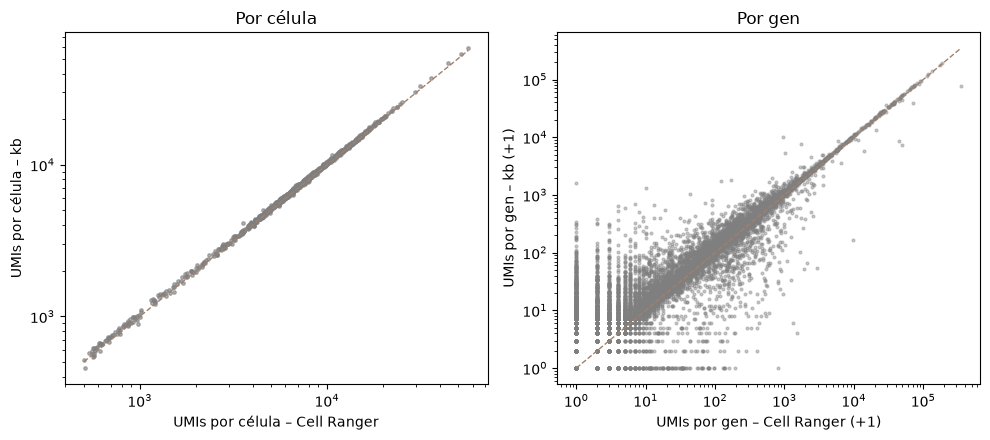

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

ax = axes[0]
ax.scatter(umis_celula_cr, umis_celula_kb, s=6, color="#7f7f7f", alpha=0.6)
lim = [umis_celula_cr.min(), umis_celula_cr.max()]
ax.plot(lim, lim, color="#a3806b", linestyle="--", linewidth=1)  # línea y = x
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("UMIs por célula – Cell Ranger")
ax.set_ylabel("UMIs por célula – kb")
ax.set_title("Por célula")

ax = axes[1]
ax.scatter(umis_gen_cr + 1, umis_gen_kb + 1, s=4, color="#7f7f7f", alpha=0.4)
lim = [1, max(umis_gen_cr.max(), umis_gen_kb.max()) + 1]
ax.plot(lim, lim, color="#a3806b", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("UMIs por gen – Cell Ranger (+1)")
ax.set_ylabel("UMIs por gen – kb (+1)")
ax.set_title("Por gen")

fig.tight_layout()
fig.savefig(RUTA_FIGURA, dpi=150, bbox_inches="tight")
plt.show()